# Data Lab




## Imports

In [91]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import zscore
from sklearn.dummy import DummyRegressor
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_regression
import os

## Load
Using ff1_spells data collection. Remove all features except level, mp, power, accuracy, target, price

Then verify the datasets contents

In [92]:
ff1_spells = pd.read_csv("./data/ff1_spells.csv", encoding="cp1252")
ff1_spells = ff1_spells [["level", "mp", "power", "accuracy", "target", "price"]]

print(ff1_spells.head())
print(ff1_spells.isnull().sum())

   level  mp  power  accuracy       target  price
0      1   5     10        24    One enemy    100
1      1   5     10        24    One enemy    100
2      1   3     20        64    One enemy    100
3      1   3      0        24  All enemies    100
4      2   5      0        24  All enemies    400
level       0
mp          0
power       0
accuracy    0
target      0
price       0
dtype: int64


## Histogram for Price feature

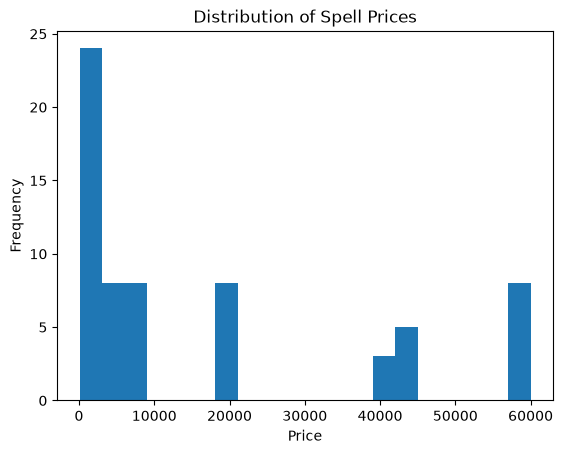

In [93]:
plt.hist(ff1_spells["price"], bins=20)
plt.title("Distribution of Spell Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

## Correlation Plot

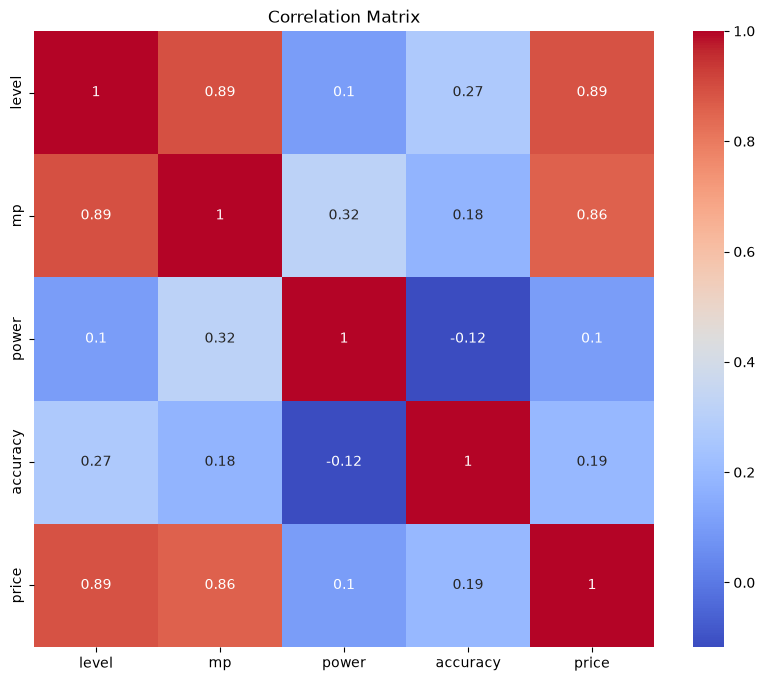

In [94]:
corr = ff1_spells.select_dtypes(include=["number"]).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

## Categorical Encode 'target' by encoding to a hot array
convert the one hot to a single dimension
Add it to the dataframe, remove original "target" feature
determine how many outliers in data
separate into X and y componets

In [95]:
target_ohe = pd.get_dummies(ff1_spells["target"])


pca = PCA(n_components=1)
target_pca = pca.fit_transform(target_ohe)


ff1_spells["target_pca"] = target_pca[:, 0]

ff1_spells = ff1_spells.drop(columns=["target"])

# Determine outliers using all numeric columns
z_score = np.abs(zscore(ff1_spells))

outlier_rows = (z_score > 3).any(axis=1)
num_outliers = outlier_rows.sum()

print(f"Number of outliers: {num_outliers}")


X = ff1_spells.drop(columns=["price"])
y = ff1_spells["price"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Explained Variance Ratio:", pca.explained_variance_ratio_)

Number of outliers: 6
X shape: (64, 5)
y shape: (64,)
Explained Variance Ratio: [0.41613412]


## Feature Selection

Use feature selection to determine which features would be best to use for the model
You don't need to act on this, just calculate the scores

In [96]:
selector = SelectKBest(score_func=f_regression, k="all")
selector.fit(X, y)


feature_scores = pd.DataFrame({ 'Feature': X.columns, 'Score': selector.scores_ })

feature_scores = feature_scores.sort_values(by="Score", ascending=False)

print(feature_scores)




      Feature       Score
0       level  237.902397
1          mp  175.768503
3    accuracy    2.405544
2       power    0.664253
4  target_pca    0.024021


## Train Model
create a dummy regressor, predict the price of a spell with the following [1, 5, 20, 50, 0.5]

In [98]:
dummy = DummyRegressor(strategy="mean")
dummy.fit(X, y)

# Example input for a spell with level=1, mp=5, power=20, accuracy=50, target_pca=0.5
prediction = dummy.predict([[1, 5, 20, 50, 0.5]])

print("Dummy Regressor Prediction for example input:", prediction[0])
print("Dummy Score: ", dummy.score(X, y))

Dummy Regressor Prediction for example input: 17140.625
Dummy Score:  0.0
